# 03 · Chẩn đoán Node2Vec: walk, p/q, độ phủ nút, pooling

> Notebook này **chỉ đọc artifact** của run (đồ thị, vector, walk, bundle). Không fit lại trên dữ liệu, không thay mô hình trong cell.
> Thử p/q cần một run riêng (`jira-ad run` với config khác), không làm trong notebook.

**Câu hỏi.**
1. Walk lấy từ DFG train trông ra sao? Có bao nhiêu walk một token / nút thiếu ngữ cảnh?
2. p và q thay đổi xác suất bước kế tiếp thế nào (kiểm chứng công thức trên đồ thị thật)?
3. Nút/chuyển tiếp ở validation/test chưa có trong train chiếm bao nhiêu (độ phủ OOV)?
4. Cosine giữa các vector nói gì — và *không* nói gì — về xác suất chuyển tiếp?
5. Hai chuỗi cùng histogram khác thứ tự: pooling thấy gì, đặc trưng chuyển tiếp thấy gì?

**Không được kết luận** từ hình PCA 2D rằng detector hiệu quả; nó chỉ để quan sát vector.

In [1]:
# Khởi tạo: mở run đã kiểm fingerprint (biến môi trường JIRA_AD_RUN_DIR do `jira-ad notebooks` đặt).
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from jira_ad.analysis import open_run

pd.options.display.float_format = "{:.3f}".format
pd.options.display.max_colwidth = 90
run = open_run()
print(run.header())

run_id      : 20261017T081309Z-930f8a85  (status: completed)
chọn run    : tự động: run hoàn tất mới nhất khớp configs/baseline.yaml hiện tại (đặt JIRA_AD_RUN_DIR để chọn run khác)
config_hash : 930f8a856d4a…  config: configs/experiments.yaml
split_hash  : a3999ae50439…  action_rules: 4a35ef7d0f48…
đầu vào     : dataset/TIeventlogBug.csv sha256=cda16f1c5c4a…; configs/actions.yaml sha256=4a35ef7d0f48…
seeds       : {'split': 42, 'model': 42, 'validation_mutation': 1042, 'test_mutation': 2042}  | cohort: bug  | methods: ['A_stats', 'B_ngrams', 'C_embedding', 'D_hybrid']


In [2]:
import networkx as nx
from scipy.stats import spearmanr

from jira_ad import plots
from jira_ad.analysis import embedding_pca, order_blindness_demo
from jira_ad.data import load_raw_events
from jira_ad.preprocess import build_core_view, load_action_rules, normalize_events
from jira_ad.walks import transition_probabilities

cfg = run.cfg
bundle = run.bundle("D_hybrid")                       # lỗi rõ nếu run không có D_hybrid
encoder = bundle.encoder
graph = nx.read_graphml(run.run_dir / "graph.graphml")  # DFG train đã lưu cùng run
diagnostics = run.read_json("embedding_diagnostics.json")
walk_sample = run.read_json("walk_sample.json")
vectors = run.read_parquet("node_vectors.parquet").set_index("node")
print(f"DFG train: {graph.number_of_nodes()} nút, {graph.number_of_edges()} cạnh; "
      f"embedding {vectors.shape[0]} nút × {vectors.shape[1]} chiều; C và D dùng chung embedding: {run.manifest['embedding_shared']}")

DFG train: 51 nút, 386 cạnh; embedding 51 nút × 16 chiều; C và D dùng chung embedding: True


## 1. Walk lấy mẫu từ DFG train

In [3]:
walks = walk_sample["walks"]
sample = pd.DataFrame({
    "walk (8 nút đầu)": [" → ".join(w[:8]) + (" …" if len(w) > 8 else "") for w in walks[:6]],
    "độ dài": [len(w) for w in walks[:6]],
})
walk_stats = diagnostics["walks"]
display(sample)
display(Markdown(
    f"Tổng **{walk_stats['n_walks']:,}** walk (p={walk_stats['p']}, q={walk_stats['q']}, dài tối đa {walk_stats['length']} nút, "
    f"{walk_stats['walks_per_node']} walk/nút); độ dài trung bình **{walk_stats['mean_walk_length']:.1f}**; "
    f"**{walk_stats['n_single_token_walks']}** walk chỉ có một token (bắt đầu từ nút không có cạnh ra, ví dụ `__END__`); "
    f"**{walk_stats['n_nodes_without_context']}** nút không có ngữ cảnh. Vector của nút học thiếu ngữ cảnh không nên diễn giải mạnh."
))

,walk (8 nút đầu),độ dài
0,STATUS_Inbox → STATUS_To Do → STATUS_In Progress → LINK_MERGE_REQUEST → LINK_MERGE_REQ...,19
1,ADD_STORY_POINTS → REMOVE_SPRINT → REMOVE_STORY_POINTS → ADD_STORY_POINTS → ADD_ISSUE_...,11
2,UPDATE_SPRINT → UPDATE_RANK → REMOVE_SPRINT → ADD_SPRINT → EDIT_DESCRIPTION → EDIT_DES...,9
3,UPDATE_FIX_VERSION → ADD_ISSUE_LINK → EDIT_DESCRIPTION → EDIT_DESCRIPTION → STATUS_INV...,17
4,__START__ → CREATE → ADD_ISSUE_LINK → EDIT_DESCRIPTION → EDIT_DESCRIPTION → EDIT_DESCR...,9
5,REMOVE_ASSIGNEE → EDIT_ISSUEPARENTASSOCIATION → UPDATE_EPIC_LINK → STATUS_Rejected → _...,5


Tổng **2,550** walk (p=1.0, q=1.0, dài tối đa 20 nút, 50 walk/nút); độ dài trung bình **13.0**; **50** walk chỉ có một token (bắt đầu từ nút không có cạnh ra, ví dụ `__END__`); **0** nút không có ngữ cảnh. Vector của nút học thiếu ngữ cảnh không nên diễn giải mạnh.

## 2. Tác động của p và q lên xác suất bước kế tiếp

In [4]:
# Chọn một cặp (t → v) có v nhiều lựa chọn nhất để thấy rõ tác động của p, q.
candidates = [(t, v) for v in graph if not v.startswith("__") and graph.out_degree(v) >= 3
              for t in graph.predecessors(v) if t != v]
t_node, v_node = max(candidates, key=lambda tv: (graph.out_degree(tv[1]), graph.get_edge_data(*tv)["weight"]))
first_order = transition_probabilities(graph, None, v_node, 1.0, 1.0)
successors = sorted(first_order, key=first_order.get, reverse=True)[:6]
settings = [(1.0, 1.0), (0.25, 1.0), (4.0, 1.0), (1.0, 0.25), (1.0, 4.0)]
rows = []
for p, q in settings:
    probs = transition_probabilities(graph, t_node, v_node, p, q)
    rows.append({"p": p, "q": q, **{s.replace("STATUS_", "S:"): probs.get(s, 0.0) for s in successors}})
pq_table = pd.DataFrame(rows)
run.save_table(pq_table, "nb03_pq_probabilities")
display(Markdown(f"Cặp minh họa: `{t_node}` → `{v_node}` (bước kế tiếp từ `{v_node}` có {graph.out_degree(v_node)} lựa chọn)."))
pq_table

Cặp minh họa: `ADD_ISSUE_LINK` → `EDIT_DESCRIPTION` (bước kế tiếp từ `EDIT_DESCRIPTION` có 29 lựa chọn).

,p,q,EDIT_DESCRIPTION,S:INVESTIGATED,LINK_COMMIT,ADD_ISSUE_LINK,ADD_FIX_VERSION,S:To Investigate
0,1.000,1.000,0.326,0.214,0.060,0.047,0.037,0.037
1,0.250,1.000,0.286,0.188,0.053,0.163,0.033,0.033
2,4.000,1.000,0.337,0.222,0.063,0.012,0.039,0.039
3,1.000,0.250,0.209,0.137,0.155,0.030,0.024,0.024
4,1.000,4.000,0.378,0.249,0.018,0.054,0.043,0.043


In [5]:
p_small = transition_probabilities(graph, t_node, v_node, 0.25, 1.0)
p_large = transition_probabilities(graph, t_node, v_node, 4.0, 1.0)
back = t_node if graph.has_edge(v_node, t_node) else None
if back is not None:
    display(Markdown(
        f"Quay lại `{back}` có xác suất **{p_small[back]:.3f}** khi p=0,25 và **{p_large[back]:.3f}** khi p=4 "
        f"(p=1: {first_order[back]:.3f} ở bước đầu). Quy ước có hướng: bias `1/p` chỉ áp dụng khi cạnh `v → t` thực sự tồn tại; "
        "không có cạnh ngược thì không tạo xác suất quay lui."
    ))
else:
    display(Markdown(
        f"Trong DFG, `{v_node}` không có cạnh quay về `{t_node}`, nên p không tác động; chỉ q phân biệt láng giềng của `{t_node}` "
        "với nút ‘ra xa’ — đúng quy ước có hướng của đề tài."
    ))

Quay lại `ADD_ISSUE_LINK` có xác suất **0.163** khi p=0,25 và **0.012** khi p=4 (p=1: 0.047 ở bước đầu). Quy ước có hướng: bias `1/p` chỉ áp dụng khi cạnh `v → t` thực sự tồn tại; không có cạnh ngược thì không tạo xác suất quay lui.

## 3. Độ phủ nút và chuyển tiếp ở validation/test

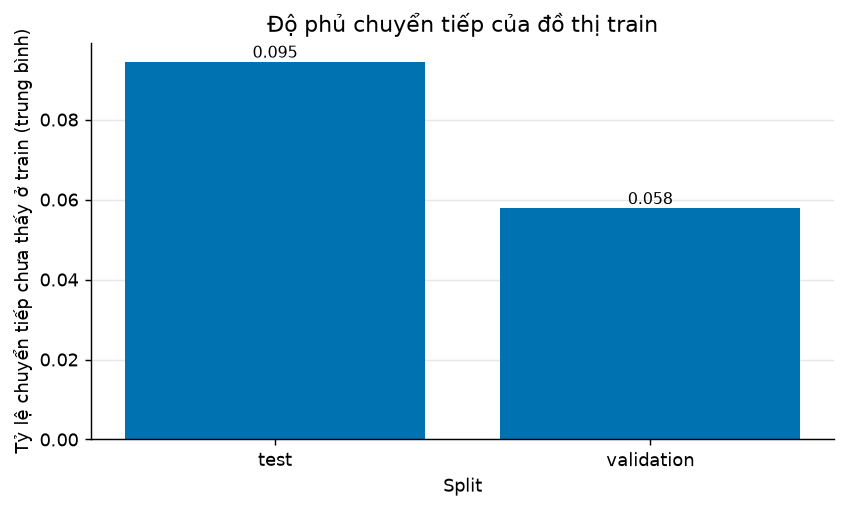

,split,unseen_node_ratio,unseen_transition_ratio
0,test,0.000,0.095
1,validation,0.000,0.058


Độ phủ nút của embedding trên đồ thị train: **100%**. Nút chưa thấy nhận vector zero (vẫn nằm trong mẫu số pooling, không retrain); chuyển tiếp chưa thấy được đo bằng `unseen_transition_ratio`.

In [6]:
scores = run.read_parquet("scores/originals.parquet")
coverage = (scores[scores.method == "D_hybrid"].groupby("split")[["unseen_node_ratio", "unseen_transition_ratio"]]
            .mean().reset_index())
fig = plots.plot_unseen_coverage(coverage)
_ = run.show(fig, "nb03_unseen_coverage", coverage)
display(coverage)
display(Markdown(
    f"Độ phủ nút của embedding trên đồ thị train: **{diagnostics['embedding']['node_coverage']:.0%}**. "
    "Nút chưa thấy nhận vector zero (vẫn nằm trong mẫu số pooling, không retrain); chuyển tiếp chưa thấy được đo bằng `unseen_transition_ratio`."
))

## 4. Cosine không phải xác suất chuyển tiếp

In [7]:
unit = vectors.div(np.linalg.norm(vectors.to_numpy(), axis=1), axis=0)
cosine = unit @ unit.T
activities = [n for n in vectors.index if not n.startswith("__")]
focus = sorted(activities, key=lambda n: -graph.nodes[n]["count"])[:4]
rows = []
for node in focus:
    out_total = graph.nodes[node]["out_count"]
    neighbours = cosine.loc[node, activities].drop(node).sort_values(ascending=False).head(3)
    for other, value in neighbours.items():
        weight = graph.get_edge_data(node, other, {}).get("weight", 0)
        rows.append({"activity": node, "gần nhất theo cosine": other, "cosine": value,
                     "P̂(đích | nguồn) thực nghiệm": weight / out_total if out_total else 0.0})
neighbour_table = pd.DataFrame(rows)
run.save_table(neighbour_table, "nb03_cosine_neighbours")
display(neighbour_table)
pairs = [(a, b) for a in activities for b in activities if a != b and graph.nodes[a]["out_count"] > 0]
cos_values = [cosine.loc[a, b] for a, b in pairs]
prob_values = [graph.get_edge_data(a, b, {}).get("weight", 0) / graph.nodes[a]["out_count"] for a, b in pairs]
rho = spearmanr(cos_values, prob_values).statistic
display(Markdown(
    f"Trên {len(pairs):,} cặp (nguồn, đích) khác nhau, Spearman giữa cosine và xác suất chuyển tiếp thực nghiệm là **{rho:.2f}**. "
    "Cosine đo độ gần trong không gian vector (đối xứng, từ ngữ cảnh trong walk), còn xác suất chuyển tiếp có hướng; "
    "không dùng cosine như xác suất, và không so cosine giữa hai không gian học độc lập."
))

,activity,gần nhất theo cosine,cosine,P̂(đích | nguồn) thực nghiệm
0,EDIT_DESCRIPTION,REMOVE_ISSUE_LINK,0.682,0.000
1,EDIT_DESCRIPTION,ADD_UNDEFINED,0.680,0.005
2,EDIT_DESCRIPTION,EDIT_SUMMARY,0.597,0.014
3,ADD_ISSUE_LINK,UPDATE_ISSUETYPE,0.592,0.000
4,ADD_ISSUE_LINK,UPDATE_LABELS,0.565,0.005
5,ADD_ISSUE_LINK,UPDATE_BACKLOG_CLASSIFICATION,0.538,0.000
6,LINK_COMMIT,LINK_MERGE_REQUEST,0.890,0.272
7,LINK_COMMIT,ADD_PARENT,0.611,0.000
8,LINK_COMMIT,ADD_ASSIGNEE,0.536,0.012
9,CREATE,STATUS_To Investigate,0.650,0.010


Trên 2,352 cặp (nguồn, đích) khác nhau, Spearman giữa cosine và xác suất chuyển tiếp thực nghiệm là **0.21**. Cosine đo độ gần trong không gian vector (đối xứng, từ ngữ cảnh trong walk), còn xác suất chuyển tiếp có hướng; không dùng cosine như xác suất, và không so cosine giữa hai không gian học độc lập.

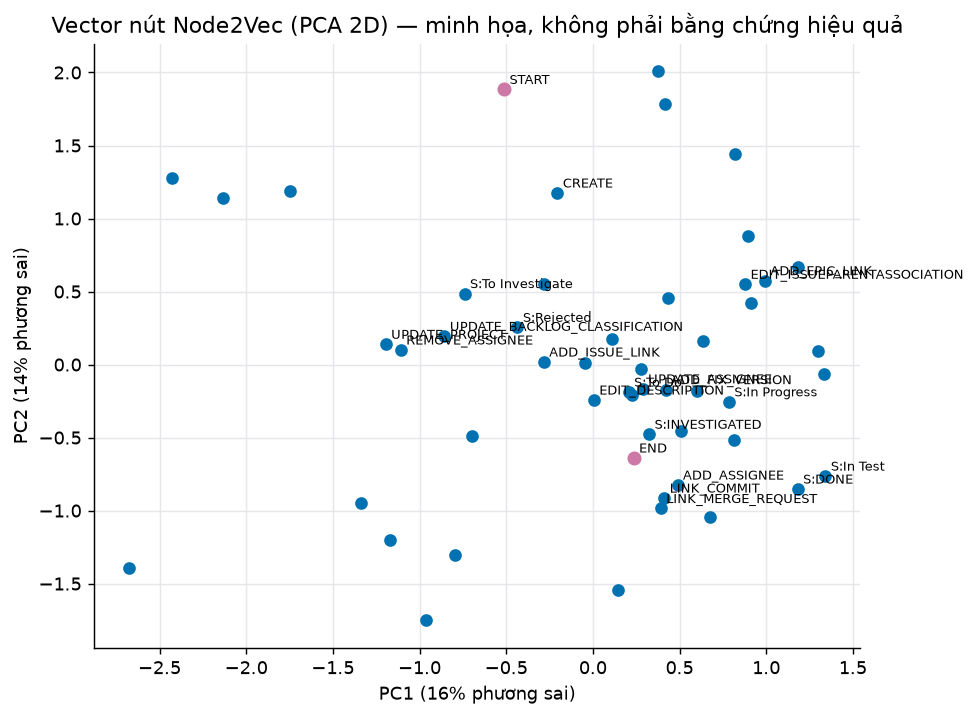

In [8]:
coords, explained = embedding_pca(vectors.to_numpy(), tuple(vectors.index))
frequent = set(sorted((n for n in vectors.index if not n.startswith("__")), key=lambda n: -graph.nodes[n]["count"])[:20])
fig = plots.plot_pca(coords, explained, label_nodes=frequent | {"__START__", "__END__"})
_ = run.show(fig, "nb03_pca", coords)

## 5. Cùng histogram, khác thứ tự: pooling mù thứ tự

In [9]:
rules = load_action_rules(cfg.preprocess.actions_path)
events = normalize_events(load_raw_events(cfg.data, run.project_root), cfg.preprocess, rules)
traces = build_core_view(events, cfg.preprocess, rules).traces
split = run.read_csv("split_manifest.csv").set_index("case_id").split
demo = None
for trace in traces:
    if split.get(trace.trace_id) == "test":
        try:
            demo = order_blindness_demo(bundle, trace)
            demo_trace = trace
            break
        except ValueError:
            continue
assert demo is not None, "không tìm được trace test có cặp activity kề nhau khác nhau để hoán đổi"
changed = [i for i, (a, b) in enumerate(zip(demo["original"], demo["swapped"])) if a != b]
display(Markdown(
    f"Trace `{demo_trace.trace_id}` ({len(demo['original'])} event): hoán đổi vị trí {changed[0] + 1}–{changed[1] + 1} "
    f"(`{demo['original'][changed[0]]}` ↔ `{demo['original'][changed[1]]}`)."
))
h_table = pd.DataFrame(demo["h_features"])
h_table["thay đổi"] = h_table["swapped"] - h_table["original"]
display(h_table[h_table["thay đổi"].abs() > 1e-12])
display(Markdown(
    f"- Chênh lệch lớn nhất ở **các cột pooling mean/max**: **{demo['pooled_max_abs_diff']:.2e}** (cùng multiset ⇒ giống hệt).\n"
    f"- Điểm D_hybrid: gốc **{demo['score_original']:.4f}** → hoán đổi **{demo['score_swapped']:.4f}**.\n"
    "- Chỉ các đặc trưng chuyển tiếp trong H (surprisal, tỷ lệ chuyển tiếp chưa thấy…) phản ứng với thay đổi thứ tự; "
    "vì vậy `C_embedding` (chỉ pooling) không thể phân biệt chúng, còn `D_hybrid` thì có thể."
))

Trace `bug:TI-4649` (6 event): hoán đổi vị trí 3–4 (`UPDATE_PROJECT` ↔ `REMOVE_ASSIGNEE`).

,feature,original,swapped,thay đổi
6,mean_transition_surprisal,1.150,2.345,1.196
7,max_transition_surprisal,2.670,4.887,2.216
9,unseen_transition_ratio,0.000,0.143,0.143


- Chênh lệch lớn nhất ở **các cột pooling mean/max**: **0.00e+00** (cùng multiset ⇒ giống hệt).
- Điểm D_hybrid: gốc **0.4797** → hoán đổi **0.4963**.
- Chỉ các đặc trưng chuyển tiếp trong H (surprisal, tỷ lệ chuyển tiếp chưa thấy…) phản ứng với thay đổi thứ tự; vì vậy `C_embedding` (chỉ pooling) không thể phân biệt chúng, còn `D_hybrid` thì có thể.

## Nhận xét (sinh từ số liệu của run này)

In [10]:
lines = [
    f"- **Walk:** {walk_stats['n_walks']:,} walk, {walk_stats['n_single_token_walks']} walk một token, "
    f"{walk_stats['n_nodes_without_context']} nút thiếu ngữ cảnh; embedding phủ {diagnostics['embedding']['node_coverage']:.0%} nút train.",
    f"- **OOV:** `unseen_transition_ratio` trung bình " + ", ".join(
        f"{r.split} {r.unseen_transition_ratio:.3f}" for r in coverage.itertuples()) + ".",
    f"- **Cosine ≠ xác suất:** Spearman(cosine, P̂) = {rho:.2f} trên {len(pairs):,} cặp.",
    f"- **Pooling mù thứ tự:** chênh lệch pooling {demo['pooled_max_abs_diff']:.1e}; H đổi ở "
    f"{int((h_table['thay đổi'].abs() > 1e-12).sum())} đặc trưng.",
]
display(Markdown("\n".join(lines)))

- **Walk:** 2,550 walk, 50 walk một token, 0 nút thiếu ngữ cảnh; embedding phủ 100% nút train.
- **OOV:** `unseen_transition_ratio` trung bình test 0.095, validation 0.058.
- **Cosine ≠ xác suất:** Spearman(cosine, P̂) = 0.21 trên 2,352 cặp.
- **Pooling mù thứ tự:** chênh lệch pooling 0.0e+00; H đổi ở 3 đặc trưng.

## Giả thuyết và giới hạn

- Random walk trên DFG có thể ghép các đoạn từ nhiều case; một walk **không phải** một trace thực tế.
- Skip-gram đối xứng nên vector không bảo đảm giữ đầy đủ quan hệ trước/sau; đó là lý do có đặc trưng chuyển tiếp riêng.
- Mean/max pooling không giữ thứ tự và không xử lý mọi phụ thuộc dài hạn; `D_hybrid` không được tuyên bố là đã xử lý chúng.
- Với ~50 nút và vài nghìn token, vector là ước lượng nhiễu; hình PCA chỉ để quan sát.